# Exploração da base: LIBRAS-HC-RGBDS no LMDB do SignEdge

A base (Porfirio et al., SMC 2013, UFPR/VRI) gravou com um Kinect as **61 configurações de mão** (CM) de Pimenta & Quadros: RGB-D 640×480, atores C1–C5 do artigo (2 tomadas cada) e uma gravação extra de 2012, **C6**, de outra pessoa em outro lugar, que é o nosso teste final fora da distribuição.

A ingestão (`make ingest`, `research.ingestion`) achou a mão com o MediaPipe no RGB, recortou um quadrado em volta dela (caixa justa × 1,75, a 288 px) junto com a profundidade alinhada e os 21 pontos, e gravou tudo num LMDB. Este notebook lê esse LMDB (precisa da base local; não roda no Colab).

**Unidade:** um clipe tem duas **pausas** (trechos com a mão parada), e de cada pausa saem até 8 frames. A pausa, não o frame, é a unidade independente: frames da mesma pausa são quase iguais.

In [1]:
import json, os, sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

from research.config import load_config
from research.ingestion.lmdb_engine import LMDBStore, unpack_sample

treino = load_config("configs/distillation.yaml")
base_cfg = load_config(treino["paths"]["data_config"])
loja = LMDBStore(RAIZ / base_cfg["paths"]["lmdb_path"], int(base_cfg["lmdb"]["map_size"]), readonly=True)
loja.__enter__()
meta = loja.read_meta()
amostras = meta["samples"]
S = int(meta["layout"]["size"])
print(f"{len(amostras)} amostras, recorte {S}×{S}; regra do recorte: {meta['crop_rule']}")

7948 amostras, recorte 288×288; regra do recorte: {'hand_center': 'meio da extensão dos 21 pontos do MediaPipe em x e em y', 'hand_side': 'maior extensão dos 21 pontos × hand_scale, piso min_box_frac × altura', 'hand_scale': 1.4, 'min_box_frac': 0.233333, 'context_scale': 1.75, 'crop_size': 288, 'two_hands': 'a mais perto da câmera (mediana da profundidade nos 21 pontos)'}


ator    frames  clipes  pausas  classes
C1        1241     119     226       61
C2        1334     120     229       61
C3        1151     121     235       61
C4        1313     121     236       61
C5        1326     122     234       61
C6        1583     121     240       61
total     7948     724    1400


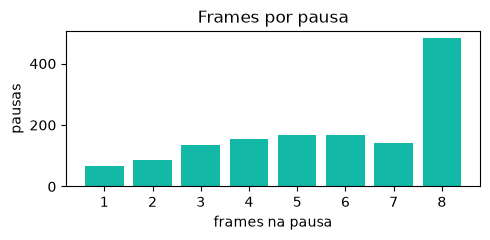

In [2]:
por_ator = defaultdict(lambda: {"frames": 0, "clipes": set(), "pausas": set(), "classes": set()})
for chave, a in amostras.items():
    r = por_ator[a["actor"]]
    r["frames"] += 1; r["clipes"].add(a["clip"]); r["pausas"].add((a["clip"], a["pause"])); r["classes"].add(a["cls"])
print(f"{'ator':6}{'frames':>8}{'clipes':>8}{'pausas':>8}{'classes':>9}")
for ator in sorted(por_ator):
    r = por_ator[ator]
    print(f"{ator:6}{r['frames']:>8}{len(r['clipes']):>8}{len(r['pausas']):>8}{len(r['classes']):>9}")
tot_p = sum(len(r["pausas"]) for r in por_ator.values())
print(f"{'total':6}{len(amostras):>8}{sum(len(r['clipes']) for r in por_ator.values()):>8}{tot_p:>8}")

frames_por_pausa = Counter(Counter((a["clip"], a["pause"]) for a in amostras.values()).values())
plt.figure(figsize=(5, 2.5)); plt.bar(list(frames_por_pausa), list(frames_por_pausa.values()), color="#14b8a6")
plt.xlabel("frames na pausa"); plt.ylabel("pausas"); plt.title("Frames por pausa"); plt.tight_layout(); plt.show()

## Profundidade alinhada à cor, por sessão

No Kinect a câmera de profundidade e a de cor ficam a alguns centímetros uma da outra, então a profundidade sai deslocada. A calibração (`make calibrate`) acha, por sessão, o deslocamento (dx, dy) que maximiza a sobreposição entre a silhueta dos 21 pontos e a superfície mais próxima. O sinal foi conferido em overlays de frames que a calibração não viu (23 de 24 corretos).

In [3]:
reg = json.loads((RAIZ / "data/processed/registration.json").read_text())
print(f"método: {reg['method']}\n")
print(f"{'sessão':8}{'dx':>5}{'dy':>5}{'IoU antes':>11}{'IoU depois':>12}{'frames':>8}")
for sessao, r in reg["sessions"].items():
    print(f"{sessao:8}{r['dx']:>5}{r['dy']:>5}{r['iou_before']:>11.3f}{r['iou_after']:>12.3f}{r['n_frames']:>8}")

método: máximo do IoU médio entre a silhueta dos 21 pontos e a superfície próxima

sessão     dx   dy  IoU antes  IoU depois  frames
C1_1       -2   14      0.443       0.532     109
C1_2       -2   20      0.325       0.411     107
C2_1        4   18      0.376       0.452     119
C2_2       -4   14      0.344       0.419     109
C3_1       -6   12      0.319       0.409     133
C3_2       -6    8      0.311       0.385      61
C4_1       -4   16      0.257       0.317     129
C4_2       -2   16      0.349       0.423      97
C5_1      -10   12      0.212       0.369     111
C5_2       -8   12      0.215       0.343     112
C6_1      -14   22      0.184       0.414     128
C6_2      -16   24      0.204       0.442     143


## Como fica uma amostra

RGB, profundidade (já alinhada) e os 21 pontos, todos no recorte de 288 px. A mesma CM em cada ator mostra o que o modelo precisa generalizar: mãos, roupas e iluminação diferentes.

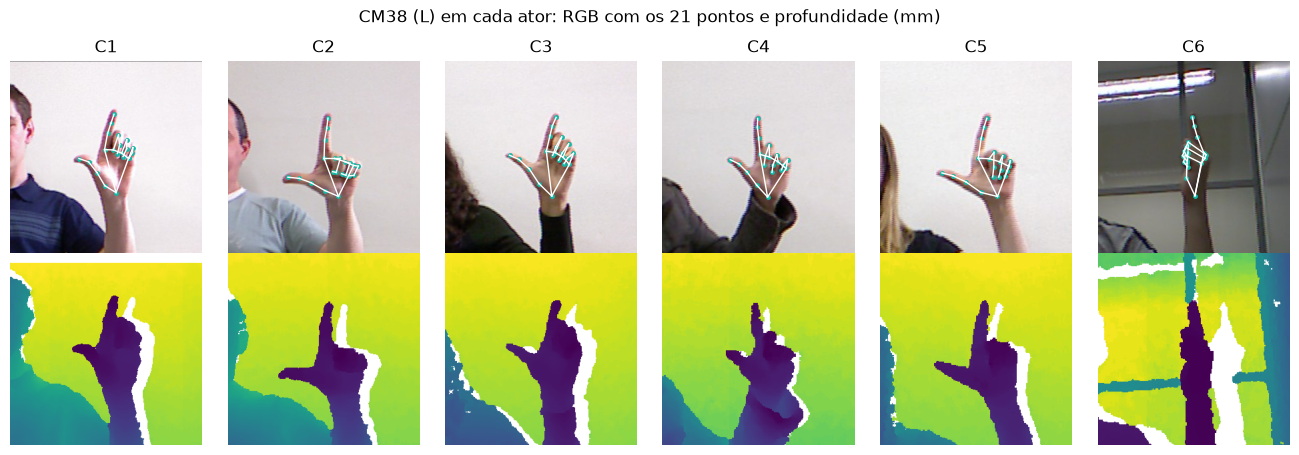

In [4]:
LIGACOES = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
            (9,13),(13,14),(14,15),(15,16),(13,17),(0,17),(17,18),(18,19),(19,20)]

def amostra(chave):
    return unpack_sample(loja.read_sample(chave.encode()), S)

def primeira(ator, cm):
    return next(k for k, a in sorted(amostras.items()) if a["actor"] == ator and a["cls"] == cm - 1)

atores = sorted(por_ator)
fig, eixos = plt.subplots(2, len(atores), figsize=(2.2 * len(atores), 4.6))
for j, ator in enumerate(atores):
    rgb, prof, pts = amostra(primeira(ator, 38))
    eixos[0, j].imshow(rgb.transpose(1, 2, 0))
    for a, b in LIGACOES:
        eixos[0, j].plot(pts[[a, b], 0], pts[[a, b], 1], color="white", lw=1)
    eixos[0, j].scatter(pts[:, 0], pts[:, 1], s=6, color="#14b8a6")
    p = prof.astype(float); p[p == 0] = np.nan
    eixos[1, j].imshow(p, cmap="viridis"); eixos[0, j].set_title(ator)
    for e in eixos[:, j]: e.axis("off")
fig.suptitle("CM38 (L) em cada ator: RGB com os 21 pontos e profundidade (mm)"); plt.tight_layout(); plt.show()

## A vista do modelo: avaliação contra treino

O modelo não vê o recorte de 288 px, e sim uma **vista 224** centrada na mão: lado = 1,5 × caixa justa, centro no meio da extensão dos 21 pontos. O app faz exatamente a mesma conta com a câmera do celular.

- `EvalView`: a vista determinística (avaliação e app).
- `TrainAugment`: a vista com o que o celular vai encontrar. Geometria (jitter de centro e escala, giro de ±15°, espelho), **fundo trocado** usando a profundidade (a superfície próxima separa mão e antebraço do resto), fotometria (balanço de branco, exposição, gama, desfoque, ruído) e pequenas oclusões. A profundidade só recebe a geometria.

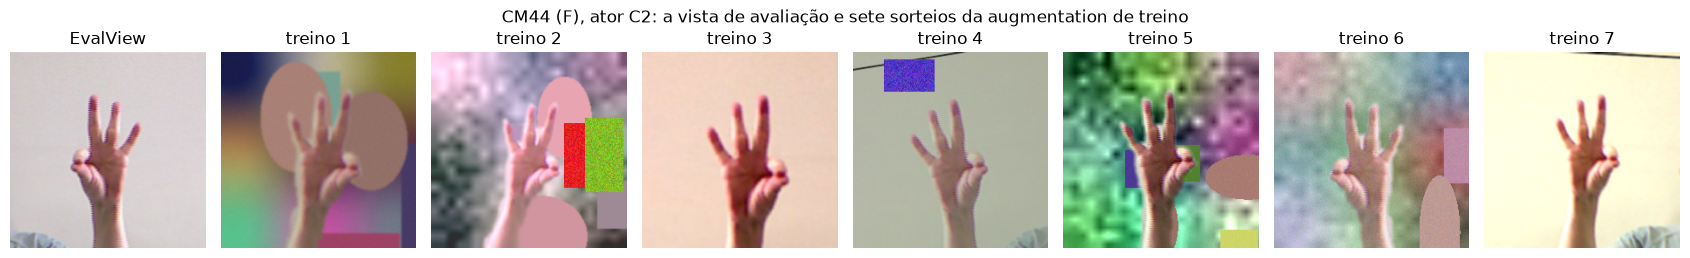

In [5]:
import torch
from research.data.augment import EvalView, TrainAugment, load_backgrounds

vista = treino["view"]
lado_mao = S / float(meta["crop_rule"]["context_scale"])
fundos = load_backgrounds(RAIZ / treino["augment"]["background"]["photo_dir"], vista["input_size"])
avaliacao = EvalView(lado_mao, vista["view_context"], vista["input_size"])
aumento = TrainAugment(treino["augment"], lado_mao, vista["view_context"], vista["input_size"], "cpu", 7, fundos)

rgb, prof, pts = amostra(primeira("C2", 44))
lote = lambda n: (torch.from_numpy(np.repeat(rgb[None], n, 0).copy()),
                  torch.from_numpy(np.repeat(prof[None].astype(np.int16), n, 0).copy()).float(),
                  torch.from_numpy(np.repeat(pts[None], n, 0).copy()))
v = avaliacao(*lote(1))
t = aumento(*lote(7))
fig, eixos = plt.subplots(1, 8, figsize=(17, 2.6))
for e, img, titulo in zip(eixos, [v["rgb"][0]] + list(t["rgb"]), ["EvalView"] + [f"treino {i+1}" for i in range(7)]):
    e.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy()); e.set_title(titulo); e.axis("off")
plt.suptitle("CM44 (F), ator C2: a vista de avaliação e sete sorteios da augmentation de treino"); plt.tight_layout(); plt.show()

## O fundo vaza a classe? (sonda de atalho)

Dentro de cada sessão, as classes foram gravadas em ordem, e a iluminação da parede muda ao longo da gravação. Um modelo poderia aprender "este tom de parede = CM 30" em vez de olhar a mão. A sonda mede isso com uma regressão logística que **só vê o que fica fora da mão** (a profundidade dá a máscara da mão), em três protocolos: LOSO (o atalho transfere para uma pessoa nova?), entre tomadas, e no próprio treino (dá para decorar?). Os 21 pontos são o controle positivo: mostram que a sonda aprende quando o sinal existe.

In [6]:
from research.data.shortcut_probe import probe

loja.__exit__(None, None, None)  # a sonda abre o LMDB por conta própria
r = probe(RAIZ / "configs/distillation.yaml", None)
print(f"{r['n_pausas']} pausas | acaso {r['acaso']:.1%} | fração do recorte fora da mão {r['fracao_contexto']:.0%}\n")
print(f"{'sinal':10}{'LOSO':>8}{'entre tomadas':>15}{'no treino':>11}")
for nome in ("context", "shape"):
    x = r[nome]
    tomadas = np.mean([t["acc"] for t in x["entre_tomadas"]])
    print(f"{('fundo' if nome == 'context' else '21 pontos'):10}{x['loso_media']:>8.1%}{tomadas:>15.1%}{x['acerto_no_treino']:>11.1%}")

1160 pausas | acaso 1.6% | fração do recorte fora da mão 76%

sinal         LOSO  entre tomadas  no treino
fundo         3.3%           4.3%      17.3%
21 pontos    59.3%          59.1%      80.2%


**Leitura.** O fundo sozinho fica perto do acaso numa pessoa nova (LOSO), e só um pouco acima dele no próprio treino: a parede vaza pouco. A forma dos 21 pontos, com o mesmo classificador linear, acerta mais da metade: o sinal está na mão. O gargalo do projeto não é atalho de fundo, é a **diversidade de sinalizantes**: com os pontos, a acurácia LOSO sobe de 54% (1 ator de treino) para 64% (2), 69% (3) e para de subir no 4º.

Próximo passo: `notebooks/minicurso_hands_on.ipynb` (poda, calibração, Int8 e o app).